# 06｜验证：如何避免把一次好结果当成规律

本书对应 ML4Trading 的研究设计和 Diagnostic 思路。使用真实 BTC 回放收益讲解分阶段、成本和连续块抽样；不安装整个机器学习工具链，也不宣称用一个检验解决了所有过拟合。

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config/research-playbook.properties").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from tools.research_playbook.data import load_frame, inventory, data_root, sha
from tools.research_playbook.analysis import plot_style
plot_style()
pd.set_option("display.max_columns", 12)

,hold,trend
day,,
2020-12-31,1.479101,1.479101
2021-12-31,0.597895,-0.216813
2022-12-31,-0.642071,0.000000
2023-12-31,1.556073,0.937498
2024-12-31,1.213058,0.807882
2025-12-31,-0.063347,-0.177262
2026-12-31,-0.075079,0.167469


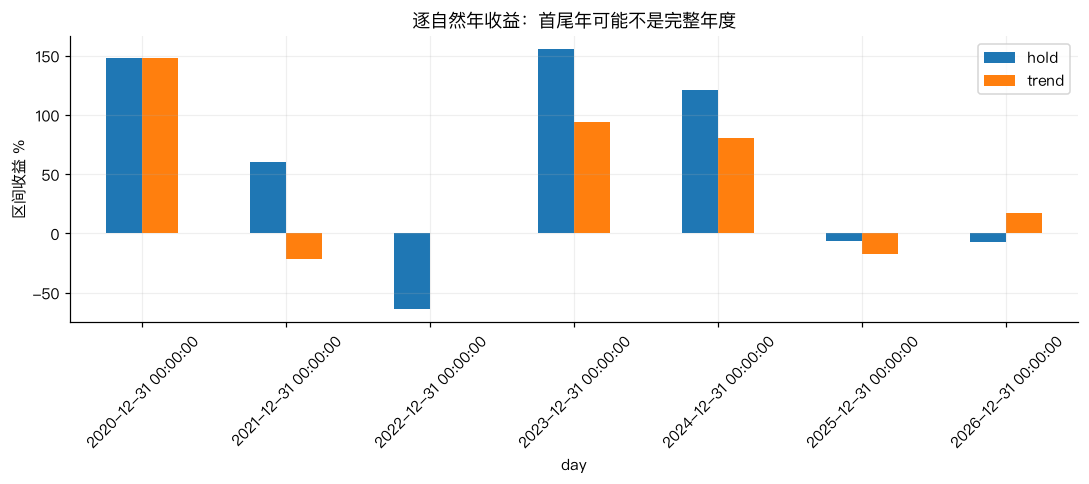

In [2]:
from tools.research_playbook.analysis import btc_baselines,block_bootstrap_mean
runs,scores=btc_baselines(load_frame("btc_daily"))
returns=pd.DataFrame({k:v["daily"].set_index("day").return_net for k,v in runs.items()})
returns.index=pd.to_datetime(returns.index)
annual=(1+returns).resample("YE").prod()-1
display(annual)
(annual*100).plot.bar(title="逐自然年收益：首尾年可能不是完整年度")
plt.ylabel("区间收益 %"); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

**读图：** 年度分段是描述，不能事后挑出“有效年份”再把其他年份删除。不同年份的波动、趋势与换手不同；必须连同失败年份报告。首尾年不足一年，因此这张图不能叫逐年年化收益。

## 1. 连续块抽样

每天独立打乱会破坏收益的局部相关性。这里对趋势规则相对买入持有的每日净收益差做 30 日连续块重采样，固定种子 42，共 1000 次，展示均值的不确定性。它不是 CAGR 差，不是完整策略路径模拟，也没有校正过去试过多少规则。

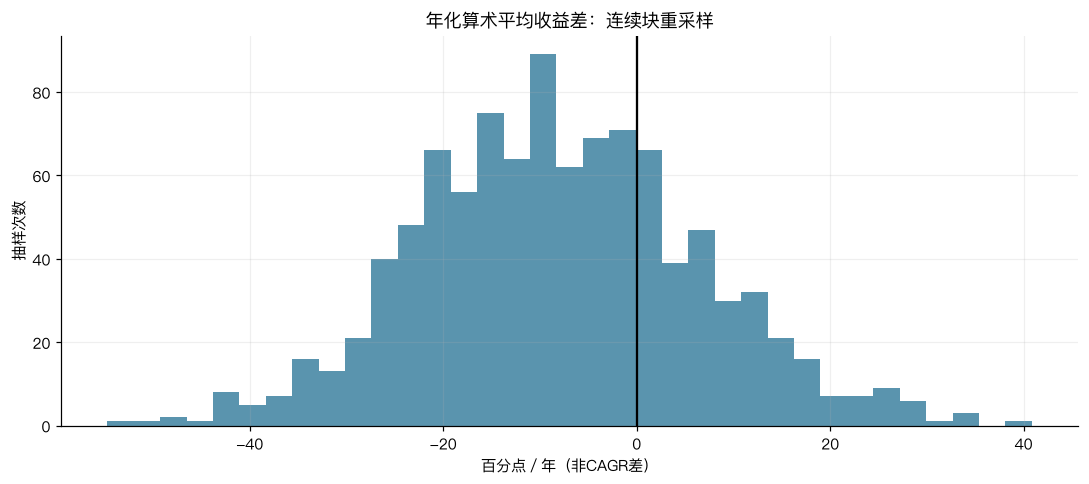

2.5%、中位数、97.5%分位： [-35.59  -8.56  22.28]


In [3]:
excess=(returns.trend-returns.hold).to_numpy()
boot=block_bootstrap_mean(excess)
ci=np.quantile(boot,[.025,.5,.975])*365*100
plt.hist(boot*365*100,bins=35,color="#317a9a",alpha=.8)
plt.axvline(0,color="black"); plt.title("年化算术平均收益差：连续块重采样")
plt.xlabel("百分点／年（非CAGR差）"); plt.ylabel("抽样次数"); plt.tight_layout(); plt.show()
print("2.5%、中位数、97.5%分位：",np.round(ci,2))

**读图：** 区间覆盖零时，这项描述不足以支持“稳定优于”的说法。不覆盖零也还需要检查非平稳性、成本、选择偏差和未见数据。块长度本身也是假设；不能为了让区间变漂亮反复更换。

## 2. 时间序列的训练标签也会泄漏

假设用未来 5 天收益作标签，即使特征只用过去，训练区最后几天的标签仍可能伸入验证区。图中训练尾部留出 5 个位置的缓冲。数字索引只是边界教学，不是拟合了一个赚钱模型。

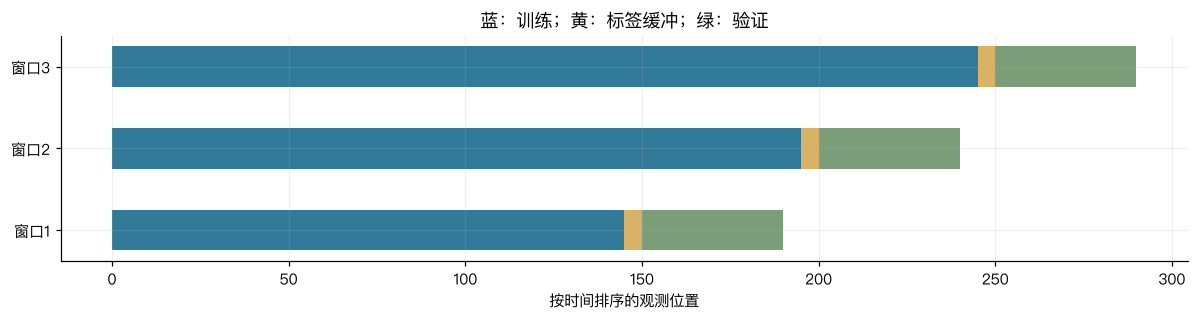

In [4]:
nobs=300; horizon=5; fig,ax=plt.subplots(figsize=(11,3))
for fold,test_start in enumerate([150,200,250]):
    train_end=test_start-horizon
    ax.broken_barh([(0,train_end)],(fold-.25,.5),facecolors="#317a9a")
    ax.broken_barh([(train_end,horizon)],(fold-.25,.5),facecolors="#d8b365")
    ax.broken_barh([(test_start,40)],(fold-.25,.5),facecolors="#7b9e78")
    assert train_end-1+horizon < test_start
ax.set_yticks([0,1,2],["窗口1","窗口2","窗口3"]); ax.set_xlabel("按时间排序的观测位置")
ax.set_title("蓝：训练；黄：标签缓冲；绿：验证"); plt.tight_layout(); plt.show()

这只检查标签末端没有跨边界。全样本标准化、用未来修订的财务数、事后选择股票池，仍会泄漏。训练变换必须在每个训练窗口内拟合。选择模型用验证集；最终评估保留未参与选择的时间段。

## 3. 多次尝试要留下账

每次记录假设、输入摘要、代码版本、规则参数、成本、试验次数、选中原因和失败项。ML4T Diagnostic 提供 DSR 等选择偏差诊断；只有一条赢家收益、却不知道尝试数量时，不应编造一个“技能概率”。

**练习：** 如果试了 200 条均线只保留收益最高的一条，下一步不是继续优化这条线，而是补齐试验账、建立固定选择流程，再等待新数据。

参考：[ML4T 时间序列验证](https://ml4trading.io/docs/diagnostic/user-guide/cross-validation/)、[DSR 方法](https://ml4trading.io/docs/diagnostic/methods/deflated-sharpe-ratio/)。